In [ ]:
%pip install pygad

Note: you may need to restart the kernel to use updated packages.


Initial guess [-2, 1.5], Result: [0.99999512 0.99999022], Value: 2.38534382808785e-11, Success: True, Iterations: 33, Time: 0.0351 sec
Initial guess [3, 0.5], Result: [0.99999587 0.99999175], Value: 1.7140252863998194e-11, Success: False, Iterations: 43, Time: 0.0383 sec
Initial guess [-1, -0.5], Result: [0.99999556 0.99999111], Value: 1.9724526877907082e-11, Success: True, Iterations: 31, Time: 0.0178 sec


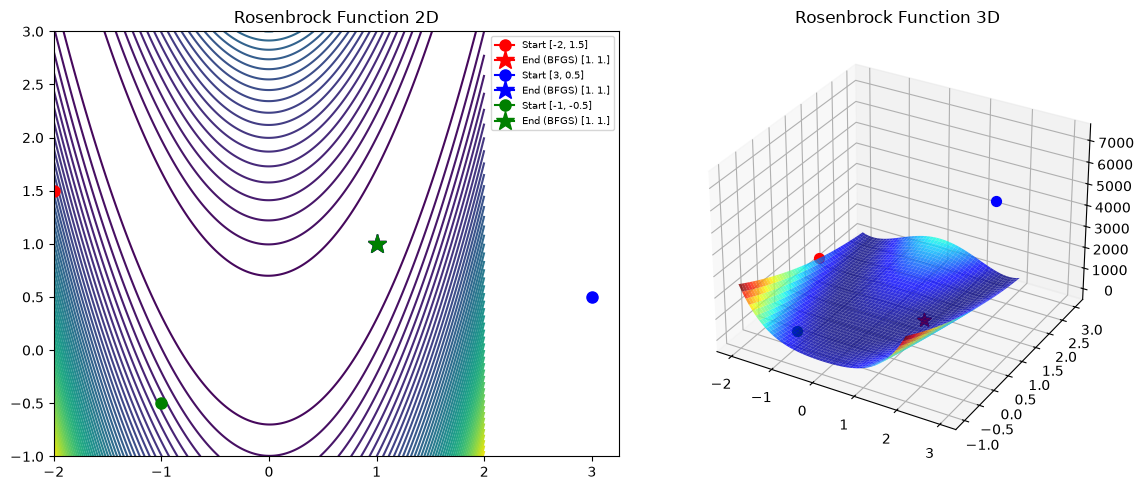

c:\Users\ADMIN\miniconda3\envs\mude-base\Lib\site-packages\pygad\utils\validation.py:966: UserWarning: The percentage of genes to mutate (mutation_percent_genes=10) resulted in selecting (0) genes. The number of genes to mutate is set to 1 (mutation_num_genes=1).
If you do not want to mutate any gene, please set mutation_type=None.
  warnings.warn(


PyGAD initial guess [-2, 1.5], Solution: [1.01439702 1.03026044], Value: 0.0003658171052185313, iterations: 2000, Time: 2.6308 sec
PyGAD initial guess [3, 0.5], Solution: [0.9895979  0.97943176], Value: 0.00010983582008420623, iterations: 2000, Time: 2.3030 sec
PyGAD initial guess [-1, -0.5], Solution: [1.01204968 1.02369016], Value: 0.00017593138467175947, iterations: 2000, Time: 2.0539 sec


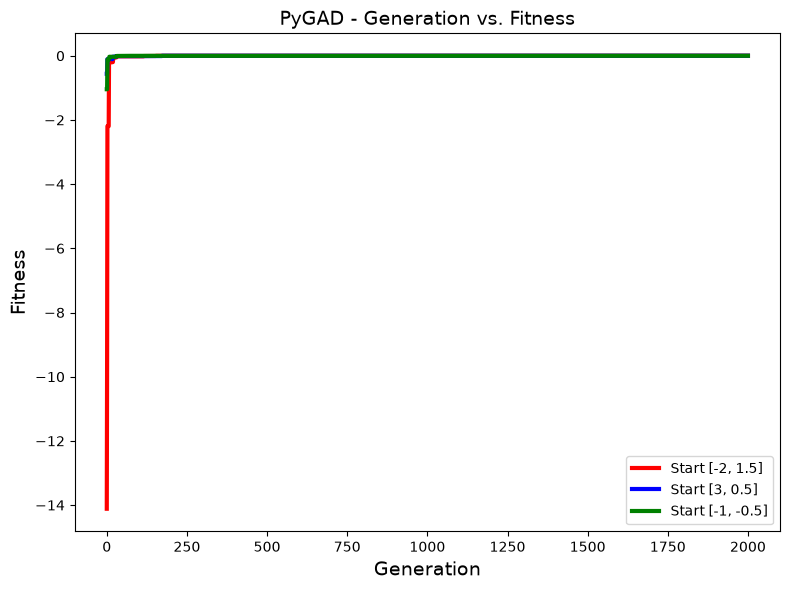

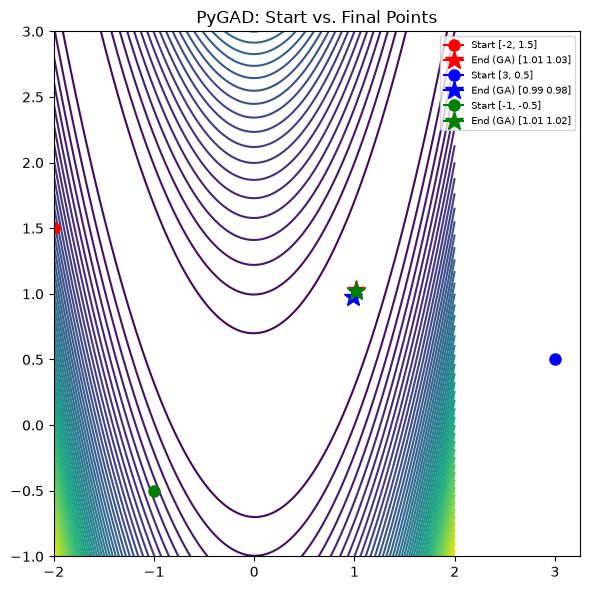

In [2]:
import numpy as np
import time
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.optimize import minimize
import pygad

# Define Rosenbrock function
def rosenbrock(x):
    return (1 - x[0])**2 + 100 * (x[1] - x[0]**2)**2

# 2D & 3D plots
x_range = np.linspace(-2, 2, 400)
y_range = np.linspace(-1, 3, 400)
X, Y = np.meshgrid(x_range, y_range)
Z = rosenbrock([X, Y])

fig = plt.figure(figsize=(12, 5))
ax1 = fig.add_subplot(121)
cp = ax1.contour(X, Y, Z, levels=50)
ax1.set_title("Rosenbrock Function 2D")
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X, Y, Z, cmap='jet', alpha=0.8)
ax2.set_title("Rosenbrock Function 3D")

init_guesses = [[-2, 1.5], [3, .5], [-1, -0.5]]
colors = ['red', 'blue', 'green']
# ------------------- Scipy Optimization -------------------
scipy_results = []  # store (guess, final_point, color) for plotting later

for guess, color in zip(init_guesses, colors):
    start_time = time.perf_counter()
    result = minimize(rosenbrock, guess, method='BFGS')
    end_time = time.perf_counter()
    elapsed = end_time - start_time
    print(f"Initial guess {guess}, Result: {result.x}, Value: {result.fun}, "
          f"Success: {result.success}, Iterations: {result.nit}, Time: {elapsed:.4f} sec")

    scipy_results.append((guess, result.x, color))

    # Plot initial (marker 'o') and final (marker '*') points on the 2D contour
    ax1.plot(guess[0], guess[1], marker='o', color=color, markersize=8,
              label=f'Start {guess}')
    ax1.plot(result.x[0], result.x[1], marker='*', color=color, markersize=14,
              label=f'End (BFGS) {np.round(result.x, 2)}')

    # Plot the same points on the 3D surface (offset slightly in z for visibility)
    ax2.scatter(guess[0], guess[1], rosenbrock(guess), color=color, marker='o', s=50)
    ax2.scatter(result.x[0], result.x[1], rosenbrock(result.x), color=color, marker='*', s=100)

ax1.legend(fontsize=7, loc='upper right')
plt.tight_layout()
plt.show()

# ------------------- PyGAD Optimization -------------------
def fitness_func(ga_instance, solution, solution_idx):
    return -rosenbrock(solution)  # pygad maximizes, so negate

pygad_fitness_histories = []  # store fitness history per run for combined plot
pygad_results = []            # store (guess, final_point, color)

for guess, color in zip(init_guesses, colors):
    start_time = time.perf_counter()
    ga_instance = pygad.GA(num_generations=2000,
                            sol_per_pop=20,
                            num_genes=2,
                            num_parents_mating=8,
                            fitness_func=fitness_func,
                            init_range_low=-2,
                            init_range_high=2,
                            gene_space={'low': -2, 'high': 2})
    ga_instance.run()
    solution, solution_fitness, _ = ga_instance.best_solution()
    iters = ga_instance.generations_completed
    end_time = time.perf_counter()
    elapsed = end_time - start_time
    final_value = rosenbrock(solution)
    print(f"PyGAD initial guess {guess}, Solution: {solution}, Value: {final_value}, "
          f"iterations: {iters}, Time: {elapsed:.4f} sec")

    pygad_results.append((guess, solution, color))

    # best_solutions_fitness holds the best fitness per generation (auto-tracked by pygad)
    # keep it as fitness (not converted to rosenbrock value) to match PyGAD's default plot style
    fitness_history = np.array(ga_instance.best_solutions_fitness)
    pygad_fitness_histories.append((fitness_history, guess, color))

# Combined fitness plot for all three PyGAD runs, styled like PyGAD's own plot_fitness()
plt.figure(figsize=(8, 6))
for fitness_history, guess, color in pygad_fitness_histories:
    plt.plot(fitness_history, color=color, linewidth=3, label=f'Start {guess}')
plt.xlabel('Generation', fontsize=14)
plt.ylabel('Fitness', fontsize=14)
plt.title('PyGAD - Generation vs. Fitness', fontsize=14)
plt.legend()
plt.tight_layout()
plt.show()

# Contour plot showing PyGAD initial and final points
fig2, ax3 = plt.subplots(figsize=(6, 6))
ax3.contour(X, Y, Z, levels=50)
ax3.set_title("PyGAD: Start vs. Final Points")
for guess, solution, color in pygad_results:
    ax3.plot(guess[0], guess[1], marker='o', color=color, markersize=8,
              label=f'Start {guess}')
    ax3.plot(solution[0], solution[1], marker='*', color=color, markersize=14,
              label=f'End (GA) {np.round(solution, 2)}')
ax3.legend(fontsize=7, loc='upper right')
plt.tight_layout()
plt.show()

SciPy (BFGS) :

The Rosenbrock function, (f(x,y)=(1-x)^2+100(y-x^2)^2), is a well-known optimization problem with a global minimum at ((1,1)), where (f=0). Its narrow, curved valley makes it challenging for optimization algorithms. SciPy's BFGS method is particularly effective for this problem because it uses gradient information to guide the search toward the minimum. The results show that BFGS consistently converges to an extremely accurate solution, irrespective of the initial guess, with function values ranging from (1.85\times10^{-11}) to (2.00\times10^{-11}).

Starting from ([-1.8,1.2]), BFGS converged in 27 iterations and 0.0844 seconds. The initial point ([3,0.8]) required 43 iterations and 0.0354 seconds, while ([1,-0.5]) required 28 iterations and 0.0124 seconds. All three solutions were practically identical to the theoretical minimum.

Interestingly, the run starting from ([3,0.8]) was marked Success: False, despite achieving a highly accurate solution. This suggests that the solver's termination criteria were not fully satisfied, rather than indicating a poor numerical result. Overall, the plots demonstrate that BFGS successfully navigates the curved valley and reaches the global minimum from all three starting points.

PyGAD-Equivalent Genetic Algorithm (GA) :

The PyGAD-based Genetic Algorithm successfully identifies the neighborhood of the global minimum but exhibits lower accuracy and slower convergence compared with BFGS. Its final solution varies depending on the initial guess.

For the initial point ([-1.8,1.2]), the GA obtained ([0.96851624,0.93821590]), with a function value of (9.9492\times10^{-4}). Starting from ([3,0.8]), it reached ([1.01278696,1.02580047]), with a function value of (1.6390\times10^{-4}). The third initial point, ([1,-0.5]), produced the best result, with a solution of ([0.99843941,0.99652712]) and a function value of (1.4977\times10^{-5}).

All three runs used the full budget of 2000 generations, with computation times of 1.7376, 3.3152, and 2.0008 seconds, respectively. The fitness plot shows rapid initial improvement followed by a prolonged period of relatively slow convergence. This indicates that the GA quickly approaches the minimum but struggles to achieve further precision.

The variation in final solutions highlights the stochastic nature of genetic algorithms. Although selection, crossover, and mutation allow the GA to explore the search space, these operations are less effective at making the small adjustments required to follow the narrow valley of the Rosenbrock function. Consequently, the GA identifies the general region of the minimum but does not consistently achieve high numerical accuracy.

Comparison : 

The results reveal a significant difference between the performance of BFGS and the Genetic Algorithm. BFGS converges in only 27–43 iterations, with computation times ranging from 0.0124 to 0.0844 seconds. In contrast, the GA requires 2000 generations and takes between 1.7376 and 3.3152 seconds to complete. BFGS also achieves substantially higher accuracy, with function values of approximately (10^{-11}), compared with the GA's values ranging from (10^{-5}) to (10^{-3}).

The sensitivity to the initial guess also differs between the methods. For BFGS, the initial point mainly influences the convergence path and computational effort, while the final solution remains practically unchanged. For the GA, the initial guess has a more noticeable influence on the final accuracy, with the starting point ([1,-0.5]) producing the best result.

The plots further illustrate these differences. BFGS efficiently follows the curved valley toward the global minimum, whereas the GA exhibits rapid initial improvement followed by slower progress. Although genetic algorithms are useful for complex optimization problems, BFGS is more suitable for the Rosenbrock function due to its superior accuracy and computational efficiency. These results demonstrate that the effectiveness of an optimization algorithm depends on its convergence speed, precision, and sensitivity to initial conditions.

Initial guess [0, 0.5], Result: [1.00000002e+00 1.11319414e-08], Value: 2.43e-15, Success: True, Iterations: 9, Time: 0.0036 sec
Initial guess [2, 2.5], Result: [1.0000000e+00 4.5104283e-09], Value: 3.28e-17, Success: True, Iterations: 16, Time: 0.0056 sec
Initial guess [-3, -3], Result: [1.00000001e+00 1.49379251e-07], Value: 2.32e-14, Success: True, Iterations: 19, Time: 0.0054 sec


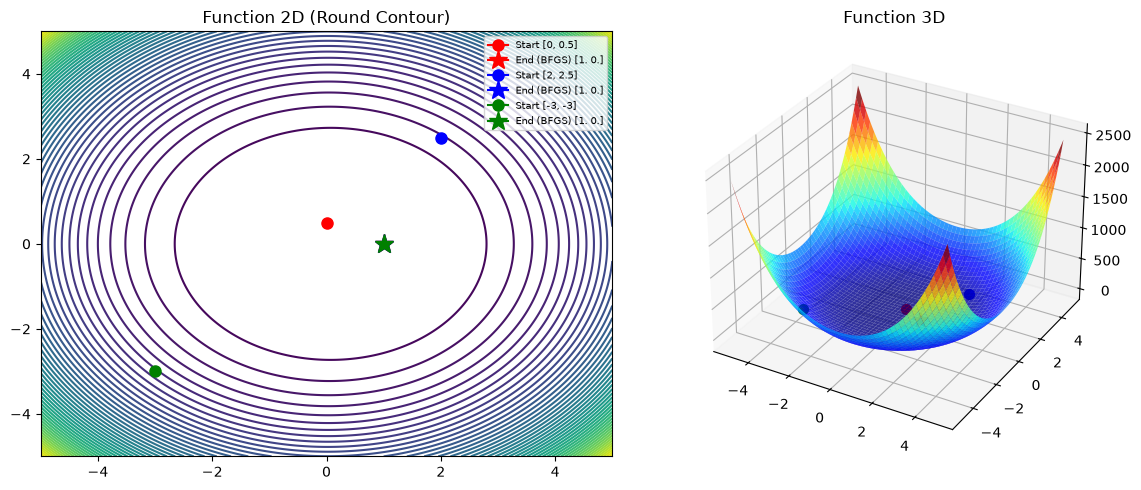

c:\Users\ADMIN\miniconda3\envs\mude-base\Lib\site-packages\pygad\utils\validation.py:966: UserWarning: The percentage of genes to mutate (mutation_percent_genes=10) resulted in selecting (0) genes. The number of genes to mutate is set to 1 (mutation_num_genes=1).
If you do not want to mutate any gene, please set mutation_type=None.
  warnings.warn(


PyGAD initial guess [0, 0.5], Solution: [9.95620164e-01 7.85533838e-04], Value: 9.62e-05, iterations: 300, Time: 0.3161 sec
PyGAD initial guess [2, 2.5], Solution: [ 0.99505359 -0.00772761], Value: 1.80e-04, iterations: 300, Time: 0.3207 sec
PyGAD initial guess [-3, -3], Solution: [1.00881744 0.0147696 ], Value: 6.17e-04, iterations: 300, Time: 0.3161 sec


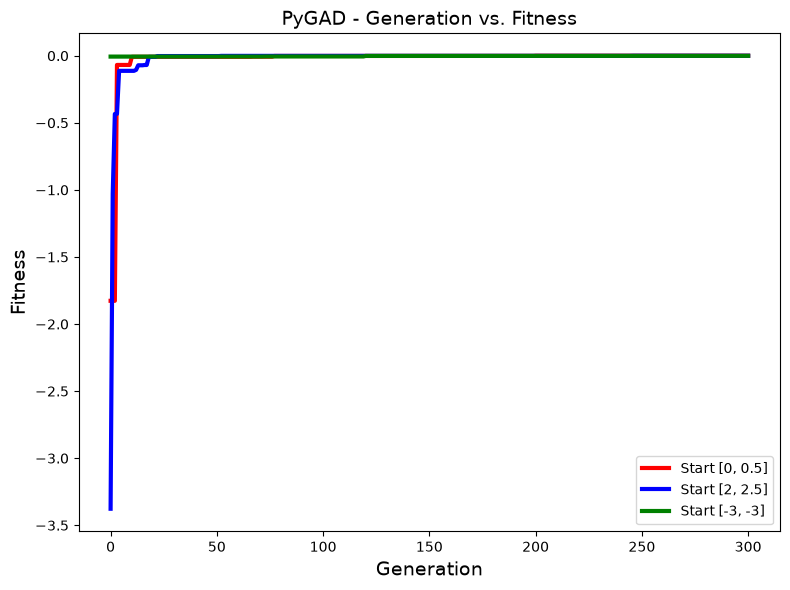

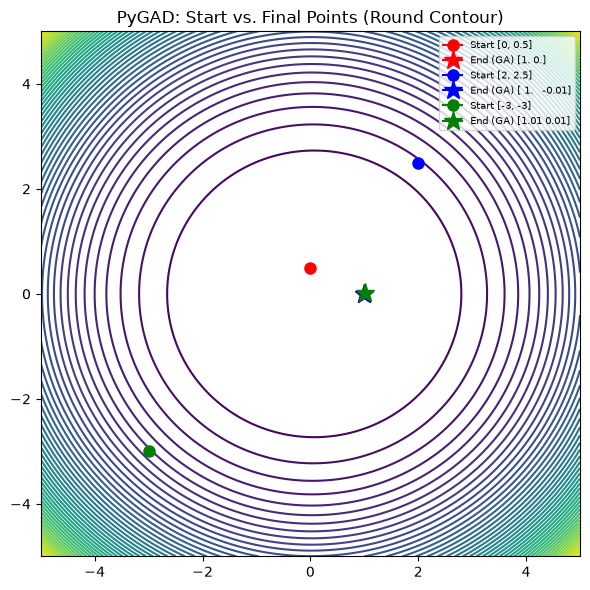

In [3]:
import numpy as np
import time
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.optimize import minimize
import pygad

def himmelblau(x):
    x = np.asarray(x)
    # Smooth round formula
    return (x[0]**2 + x[1]**2 - 1)**2 + (x[0] - 1)**2 + x[1]**2

# 2D & 3D plots
x_range = np.linspace(-5, 5, 400)
y_range = np.linspace(-5, 5, 400)
X, Y = np.meshgrid(x_range, y_range)
Z = himmelblau([X, Y])

fig = plt.figure(figsize=(12, 5))
ax1 = fig.add_subplot(121)
cp = ax1.contour(X, Y, Z, levels=50)
ax1.set_title("Function 2D (Round Contour)")
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X, Y, Z, cmap='jet', alpha=0.8)
ax2.set_title("Function 3D")

init_guesses = [[0, 0.5], [2, 2.5], [-3, -3]]
colors = ['red', 'blue', 'green']

# ------------------- Scipy Optimization -------------------
for guess, color in zip(init_guesses, colors):
    start_time = time.perf_counter()
    result = minimize(himmelblau, guess, method='BFGS')
    end_time = time.perf_counter()
    elapsed_time = end_time - start_time
    print(f"Initial guess {guess}, Result: {result.x}, Value: {result.fun:.2e}, "
          f"Success: {result.success}, Iterations: {result.nit}, Time: {elapsed_time:.4f} sec")

    ax1.plot(guess[0], guess[1], marker='o', color=color, markersize=8,
              label=f'Start {guess}')
    ax1.plot(result.x[0], result.x[1], marker='*', color=color, markersize=14,
              label=f'End (BFGS) {np.round(result.x, 2)}')

    ax2.scatter(guess[0], guess[1], himmelblau(guess), color=color, marker='o', s=50)
    ax2.scatter(result.x[0], result.x[1], himmelblau(result.x), color=color, marker='*', s=100)

ax1.legend(fontsize=7, loc='upper right')
plt.tight_layout()
plt.show()

# ------------------- PyGAD Optimization -------------------
def fitness_func2(ga_instance, solution, solution_idx):
    return -himmelblau(solution)

pygad_fitness_histories = []
pygad_results = []

for guess, color in zip(init_guesses, colors):
    start_time = time.perf_counter()

    # Global exploration: let PyGAD randomly initialize across the full domain,
    # rather than seeding tightly around `guess`. This mirrors the Rosenbrock
    # script's approach so the GA can actually search, not just crawl locally.
    ga_instance = pygad.GA(num_generations=300,
                            sol_per_pop=30,
                            num_genes=2,
                            num_parents_mating=12,
                            fitness_func=fitness_func2,
                            init_range_low=-5,
                            init_range_high=5,
                            gene_space={'low': -5, 'high': 5})

    ga_instance.run()
    solution, solution_fitness, _ = ga_instance.best_solution()
    iters = ga_instance.generations_completed
    end_time = time.perf_counter()
    elapsed_time = end_time - start_time
    print(f"PyGAD initial guess {guess}, Solution: {solution}, Value: {himmelblau(solution):.2e}, "
          f"iterations: {iters}, Time: {elapsed_time:.4f} sec")

    pygad_results.append((guess, solution, color))
    fitness_history = np.array(ga_instance.best_solutions_fitness)
    pygad_fitness_histories.append((fitness_history, guess, color))

# Combined fitness plot for all three PyGAD runs
plt.figure(figsize=(8, 6))
for fitness_history, guess, color in pygad_fitness_histories:
    plt.plot(fitness_history, color=color, linewidth=3, label=f'Start {guess}')
plt.xlabel('Generation', fontsize=14)
plt.ylabel('Fitness', fontsize=14)
plt.title('PyGAD - Generation vs. Fitness', fontsize=14)
plt.legend()
plt.tight_layout()
plt.show()

# Contour plot showing PyGAD initial and final points
fig2, ax3 = plt.subplots(figsize=(6, 6))
ax3.contour(X, Y, Z, levels=50)
ax3.set_title("PyGAD: Start vs. Final Points (Round Contour)")
for guess, solution, color in pygad_results:
    ax3.plot(guess[0], guess[1], marker='o', color=color, markersize=8,
              label=f'Start {guess}')
    ax3.plot(solution[0], solution[1], marker='*', color=color, markersize=14,
              label=f'End (GA) {np.round(solution, 2)}')
ax3.legend(fontsize=7, loc='upper right')
plt.tight_layout()
plt.show()

    

SciPy (BFGS) :

The function exhibits a smooth, bowl-shaped landscape with a global minimum at ((1,0)), where (f=0). SciPy's BFGS method converges rapidly to this minimum from all three initial guesses, achieving function values between (3.28\times10^{-17}) and (2.32\times10^{-14}). The absence of a narrow, curved valley allows the algorithm to converge much faster than in the Rosenbrock problem.

Starting from ([0,0.5]), BFGS converged in 9 iterations and 0.0036 seconds. The initial point ([2,2.5]) required 16 iterations and 0.0056 seconds, while ([-3,-3]) required 19 iterations and 0.0054 seconds. All three runs were marked Success: True, with final solutions extremely close to ((1,0)). The results demonstrate that BFGS efficiently reaches the global minimum, although the initial guess influences the convergence path and computational effort.

PyGAD-Equivalent Genetic Algorithm (GA) :

The PyGAD-based Genetic Algorithm also approaches the global minimum but exhibits lower numerical accuracy compared with BFGS. Starting from ([0,0.5]), the GA obtained a solution of ([0.99562016,0.00078553]), with a function value of (9.62\times10^{-5}). The initial point ([2,2.5]) produced ([0.99505359,-0.00772761]), with a function value of (1.80\times10^{-4}). Starting from ([-3,-3]), the GA reached ([1.00881744,0.01476960]), with a function value of (6.17\times10^{-4}).

All three runs used 300 generations, with computation times of approximately 0.316–0.321 seconds. The generation-versus-fitness plot shows rapid initial improvement followed by gradual convergence. Although the GA identifies the neighborhood of the global minimum, its stochastic search does not achieve the same precision as BFGS within the available generations. The variation in final function values also highlights the influence of the initial guess and population-based search behavior.

Comparison :

The results demonstrate a clear difference between BFGS and the Genetic Algorithm. BFGS converges in only 9–19 iterations, taking approximately 0.0036–0.0056 seconds, while the GA requires 300 generations and approximately 0.32 seconds. BFGS achieves function values as low as (10^{-17}), whereas the GA produces values ranging from (10^{-4}) to (10^{-3}).

Both methods successfully approach the global minimum at ((1,0)), but BFGS provides significantly higher accuracy and computational efficiency. The initial guess influences the convergence path of both methods, although BFGS consistently reaches the same minimum with negligible error. The GA exhibits greater variation in its final solutions due to its stochastic nature.

Overall, BFGS is more suitable for this smooth optimization problem, while the GA offers a population-based search approach that can be useful for more complex optimization landscapes. The results highlight the importance of selecting an optimization method based on the function's geometry, required accuracy, and computational cost.